# FFNN — 1A, 1B, 1C, 1E

This keeps your original Dense(128) + softmax + SGD structure. Dataset selection is built in.

In [7]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import models, layers, datasets

In [8]:
train = pd.read_csv("sign_mnist_train.csv")
test = pd.read_csv("sign_mnist_test.csv")

# Separate labels and features
y_train = train.iloc[:,0].values
x_train = train.iloc[:,1:].values

y_test = test.iloc[:,0].values
x_test = test.iloc[:,1:].values

# Normalize data
x_train = x_train.astype("float32")/255
x_test = x_test.astype("float32")/255

# Flatten images
x_train = x_train.reshape(len(x_train),-1)
x_test = x_test.reshape(len(x_test),-1)


In [13]:
model = models.Sequential([
    layers.Input(shape=(x_train.shape[1],)),
    layers.Dense(128, activation="relu"),
    layers.Dense(26, activation="softmax")
])
model.compile(optimizer="sgd", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
history = model.fit(x_train, y_train, epochs=11,
                    batch_size=32, validation_split=0.1)
loss, acc = model.evaluate(x_test, y_test)
print("Test Accuracy:", acc, "Test Loss:", loss)


Epoch 1/11
773/773 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.2385 - loss: 2.7384 - val_accuracy: 0.3219 - val_loss: 2.3362
Epoch 2/11
773/773 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.4733 - loss: 1.9926 - val_accuracy: 0.4727 - val_loss: 1.7930
Epoch 3/11
773/773 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.5797 - loss: 1.5756 - val_accuracy: 0.5590 - val_loss: 1.4867
Epoch 4/11
773/773 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.6430 - loss: 1.3261 - val_accuracy: 0.6264 - val_loss: 1.2837
Epoch 5/11
773/773 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.6868 - loss: 1.1558 - val_accuracy: 0.6788 - val_loss: 1.1386
Epoch 6/11
773/773 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.7190 - loss: 1.0283 - val_accuracy: 0.7160 - val_loss: 1.0246
Epoch 7/11
773/773 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.7486 - loss: 0.9273 - val_accuracy: 0.7305 - val_loss: 0.9376
Epoch 8/11
773/773 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.7719 - loss: 0.8442 - val_accuracy: 0.

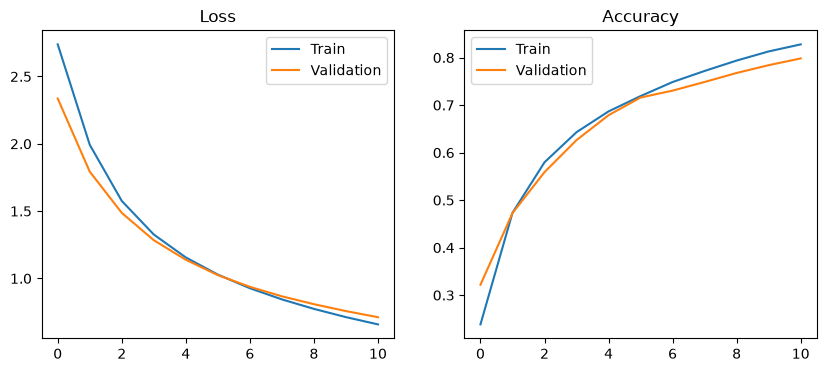

In [14]:
plt.figure(figsize=(10,4))
plt.subplot(1,2,1); plt.plot(history.history["loss"]); plt.plot(history.history["val_loss"]); plt.title("Loss"); plt.legend(["Train","Validation"])
plt.subplot(1,2,2); plt.plot(history.history["accuracy"]); plt.plot(history.history["val_accuracy"]); plt.title("Accuracy"); plt.legend(["Train","Validation"])
plt.show()
